# Brain MRI Tumor Segmentation with DeepLabV3+

Patient-level brain tumor segmentation on the LGG MRI Segmentation dataset using DeepLabV3+ with an ImageNet-pretrained MobileNetV2 encoder.

## Project overview

This notebook downloads the dataset directly from Kaggle, creates leakage-safe patient-level train/validation/test splits, trains a DeepLabV3+ model, selects the segmentation threshold only on the validation set, and reports final test metrics.

Main evaluation metrics:

- Global Dice and IoU
- Mean per-image Dice and IoU
- Tumor-positive image Dice and IoU
- Precision, recall, specificity, and pixel accuracy
- False-positive rate on tumor-free slices

> Recommended runtime: Google Colab with a GPU accelerator.

In [1]:
!pip install -q kagglehub

In [2]:
import json
import random
from pathlib import Path

import cv2
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras import Model, layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Download and inspect the dataset

The dataset is downloaded through kagglehub; no manual upload is required. A single canonical kaggle_3m directory is selected to prevent duplicate counting when the archive contains nested copies.

In [3]:
dataset_path = Path(kagglehub.dataset_download("mateuszbuda/lgg-mri-segmentation"))

direct_root = dataset_path / "kaggle_3m"
if direct_root.is_dir():
    data_root = direct_root
else:
    candidates = sorted(
        [path for path in dataset_path.rglob("kaggle_3m") if path.is_dir()],
        key=lambda path: (len(path.parts), str(path))
    )
    if not candidates:
        raise FileNotFoundError("The kaggle_3m directory was not found.")
    data_root = candidates[0]

patient_dirs = sorted(path for path in data_root.iterdir() if path.is_dir())

print("Dataset cache:", dataset_path)
print("Selected data root:", data_root)
print("Patients:", len(patient_dirs))

Using Colab cache for faster access to the 'lgg-mri-segmentation' dataset.
Dataset cache: /kaggle/input/lgg-mri-segmentation
Selected data root: /kaggle/input/lgg-mri-segmentation/kaggle_3m
Patients: 110


In [4]:
def get_image_mask_pairs(directories):
    image_paths = []
    mask_paths = []

    for patient_dir in directories:
        for image_path in sorted(patient_dir.glob("*.tif")):
            if image_path.name.endswith("_mask.tif"):
                continue

            mask_path = image_path.with_name(f"{image_path.stem}_mask.tif")
            if mask_path.exists():
                image_paths.append(str(image_path))
                mask_paths.append(str(mask_path))

    return image_paths, mask_paths

def mask_is_positive(mask_path):
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise FileNotFoundError(f"Could not read mask: {mask_path}")
    return bool(np.any(mask > 0))

all_images, all_masks = get_image_mask_pairs(patient_dirs)
all_positive_count = sum(mask_is_positive(path) for path in all_masks)

print("Unique image-mask pairs:", len(all_images))
print("Tumor-positive slices:", all_positive_count)
print("Tumor-free slices:", len(all_masks) - all_positive_count)

Unique image-mask pairs: 3929
Tumor-positive slices: 1373
Tumor-free slices: 2556


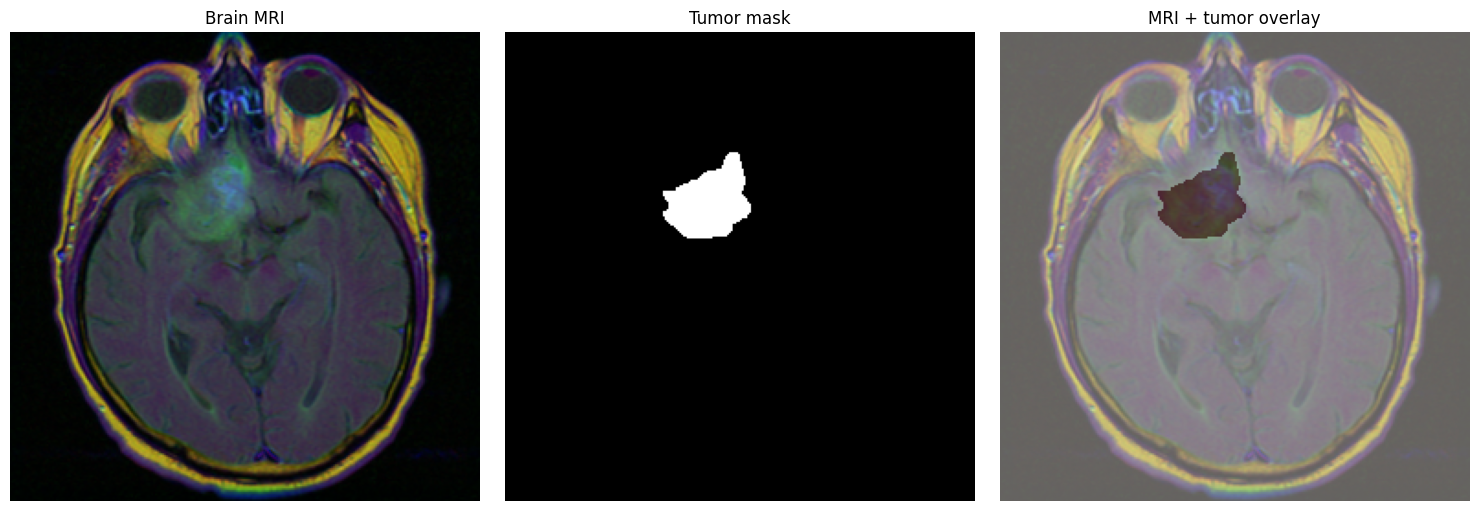

In [5]:
positive_index = next(index for index, path in enumerate(all_masks) if mask_is_positive(path))
sample_image = cv2.cvtColor(cv2.imread(all_images[positive_index]), cv2.COLOR_BGR2RGB)
sample_mask = cv2.imread(all_masks[positive_index], cv2.IMREAD_GRAYSCALE)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(sample_image)
axes[0].set_title("Brain MRI")
axes[1].imshow(sample_mask, cmap="gray")
axes[1].set_title("Tumor mask")
axes[2].imshow(sample_image)
axes[2].imshow(sample_mask, cmap="Reds", alpha=0.4)
axes[2].set_title("MRI + tumor overlay")

for axis in axes:
    axis.axis("off")

plt.tight_layout()
plt.show()

## 2. Leakage-safe patient-level split

All slices from the same patient remain in one subset. The split is stratified by whether a patient has at least one tumor-positive mask.

In [6]:
def patient_has_tumor(patient_dir):
    return int(any(mask_is_positive(path) for path in patient_dir.glob("*_mask.tif")))

patient_labels = [patient_has_tumor(path) for path in patient_dirs]

train_dirs, temporary_dirs, _, temporary_labels = train_test_split(
    patient_dirs,
    patient_labels,
    test_size=0.20,
    random_state=SEED,
    stratify=patient_labels
)

val_dirs, test_dirs = train_test_split(
    temporary_dirs,
    test_size=0.50,
    random_state=SEED,
    stratify=temporary_labels
)

train_images, train_masks = get_image_mask_pairs(train_dirs)
val_images, val_masks = get_image_mask_pairs(val_dirs)
test_images, test_masks = get_image_mask_pairs(test_dirs)

def split_summary(name, directories, image_paths, mask_paths):
    positive_count = sum(mask_is_positive(path) for path in mask_paths)
    return {
        "split": name,
        "patients": len(directories),
        "slices": len(image_paths),
        "positive_slices": positive_count,
        "empty_slices": len(mask_paths) - positive_count
    }

split_df = pd.DataFrame([
    split_summary("Train", train_dirs, train_images, train_masks),
    split_summary("Validation", val_dirs, val_images, val_masks),
    split_summary("Test", test_dirs, test_images, test_masks)
])
split_df

,split,patients,slices,positive_slices,empty_slices
0,Train,88,3165,1137,2028
1,Validation,11,386,109,277
2,Test,11,378,127,251


## 3. Input pipeline

MRI images are resized to 256 × 256 and mapped to the [-1, 1] input range expected by MobileNetV2. Masks use nearest-neighbor resizing and remain binary.

In [7]:
IMG_SIZE = 256
BATCH_SIZE = 8
AUTOTUNE = tf.data.AUTOTUNE

def read_pair(image_path, mask_path):
    image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

    if image is None or mask is None:
        raise FileNotFoundError(f"Could not read pair: {image_path}, {mask_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
    image = image.astype(np.float32) / 127.5 - 1.0

    mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    mask = (mask > 0).astype(np.float32)[..., None]

    return image, mask

def load_pair_numpy(image_path, mask_path):
    return read_pair(image_path.decode("utf-8"), mask_path.decode("utf-8"))

def load_pair_tensor(image_path, mask_path):
    image, mask = tf.numpy_function(
        load_pair_numpy,
        [image_path, mask_path],
        [tf.float32, tf.float32]
    )
    image.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return image, mask

def augment_pair(image, mask):
    flip = tf.random.uniform(()) > 0.5
    image = tf.cond(flip, lambda: tf.image.flip_left_right(image), lambda: image)
    mask = tf.cond(flip, lambda: tf.image.flip_left_right(mask), lambda: mask)
    image = tf.image.random_brightness(image, max_delta=0.08)
    image = tf.image.random_contrast(image, lower=0.90, upper=1.10)
    image = tf.clip_by_value(image, -1.0, 1.0)
    return image, mask

def build_dataset(image_paths, mask_paths, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(image_paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(load_pair_tensor, num_parallel_calls=AUTOTUNE)

    if training:
        dataset = dataset.map(augment_pair, num_parallel_calls=AUTOTUNE)

    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = build_dataset(train_images, train_masks, training=True)
val_ds = build_dataset(val_images, val_masks)
test_ds = build_dataset(test_images, test_masks)

In [8]:
sample_batch_images, sample_batch_masks = next(iter(train_ds))

print("Image batch shape:", sample_batch_images.shape)
print("Mask batch shape:", sample_batch_masks.shape)
print("Image range:", float(tf.reduce_min(sample_batch_images)), float(tf.reduce_max(sample_batch_images)))
print("Mask values:", np.unique(sample_batch_masks.numpy()))

Image batch shape: (8, 256, 256, 3)
Mask batch shape: (8, 256, 256, 1)
Image range: -1.0 0.8605769276618958
Mask values: [0. 1.]


## 4. Loss and training metrics

The loss combines binary cross-entropy with per-image soft Dice loss. Final reported metrics are calculated separately after threshold selection.

In [9]:
def soft_dice_coefficient(y_true, y_pred, smooth=1e-6):
    axes = (1, 2, 3)
    intersection = tf.reduce_sum(y_true * y_pred, axis=axes)
    denominator = tf.reduce_sum(y_true, axis=axes) + tf.reduce_sum(y_pred, axis=axes)
    score = (2.0 * intersection + smooth) / (denominator + smooth)
    return tf.reduce_mean(score)

def soft_iou_coefficient(y_true, y_pred, smooth=1e-6):
    axes = (1, 2, 3)
    intersection = tf.reduce_sum(y_true * y_pred, axis=axes)
    union = (
        tf.reduce_sum(y_true, axis=axes)
        + tf.reduce_sum(y_pred, axis=axes)
        - intersection
    )
    score = (intersection + smooth) / (union + smooth)
    return tf.reduce_mean(score)

def bce_dice_loss(y_true, y_pred):
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return bce + (1.0 - soft_dice_coefficient(y_true, y_pred))

## 5. DeepLabV3+ with MobileNetV2 encoder

The decoder combines ASPP context features with low-level spatial features from MobileNetV2. The encoder is frozen during warm-up and partially unfrozen for fine-tuning.

In [10]:
def convolution_block(x, filters=256, kernel_size=3, dilation_rate=1):
    x = layers.Conv2D(
        filters,
        kernel_size,
        padding="same",
        dilation_rate=dilation_rate,
        use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation("relu")(x)

def aspp_block(x):
    height, width = int(x.shape[1]), int(x.shape[2])

    pooled = layers.GlobalAveragePooling2D(keepdims=True)(x)
    pooled = convolution_block(pooled, filters=256, kernel_size=1)
    pooled = layers.Resizing(height, width, interpolation="bilinear")(pooled)

    branch_1 = convolution_block(x, filters=256, kernel_size=1, dilation_rate=1)
    branch_2 = convolution_block(x, filters=256, kernel_size=3, dilation_rate=6)
    branch_3 = convolution_block(x, filters=256, kernel_size=3, dilation_rate=12)
    branch_4 = convolution_block(x, filters=256, kernel_size=3, dilation_rate=18)

    x = layers.Concatenate()([pooled, branch_1, branch_2, branch_3, branch_4])
    return convolution_block(x, filters=256, kernel_size=1)

def build_deeplabv3plus(input_shape=(256, 256, 3)):
    inputs = layers.Input(shape=input_shape)

    backbone = tf.keras.applications.MobileNetV2(
        input_tensor=inputs,
        weights="imagenet",
        include_top=False
    )
    backbone.trainable = False

    low_level = backbone.get_layer("block_3_expand_relu").output
    encoder_output = backbone.get_layer("block_13_expand_relu").output

    x = aspp_block(encoder_output)
    x = layers.Resizing(
        int(low_level.shape[1]),
        int(low_level.shape[2]),
        interpolation="bilinear"
    )(x)

    low_level = convolution_block(low_level, filters=48, kernel_size=1)
    x = layers.Concatenate()([x, low_level])
    x = convolution_block(x, filters=256, kernel_size=3)
    x = convolution_block(x, filters=256, kernel_size=3)
    x = layers.Resizing(input_shape[0], input_shape[1], interpolation="bilinear")(x)
    outputs = layers.Conv2D(1, kernel_size=1, activation="sigmoid")(x)

    model = Model(inputs, outputs, name="DeepLabV3Plus_MobileNetV2")
    return model, backbone

model, backbone = build_deeplabv3plus((IMG_SIZE, IMG_SIZE, 3))
model.summary()

/tmp/ipykernel_568/4252775762.py:30: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  backbone = tf.keras.applications.MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "DeepLabV3Plus_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 128, 128,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 128, 128,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 128, 128,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 128, 128,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 128, 128,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 128, 128,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 128, 128,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 128, 128,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 128, 128,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 128, 128,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 128, 128,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 129, 129,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 64, 64,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 64, 64,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 64, 64,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 64, 64,    │      2,304 │ block_1_depthwis

 Total params: 6,525,953 (24.89 MB)

 Trainable params: 5,905,505 (22.53 MB)

 Non-trainable params: 620,448 (2.37 MB)

## 6. Training

Training uses two stages: decoder warm-up with the encoder frozen, followed by low-learning-rate fine-tuning of the final MobileNetV2 layers.

In [11]:
BEST_MODEL_PATH = "best_deeplabv3plus_brain_mri.keras"
WARMUP_WEIGHTS_PATH = "warmup_best.weights.h5"
FINE_TUNE_WEIGHTS_PATH = "finetune_best.weights.h5"
WARMUP_EPOCHS = 5
FINE_TUNE_EPOCHS = 20

def compile_model(model, learning_rate):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss=bce_dice_loss,
        metrics=[soft_dice_coefficient, soft_iou_coefficient]
    )

def make_callbacks(checkpoint_path):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            checkpoint_path,
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            save_weights_only=True,
            verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            mode="min",
            factor=0.5,
            patience=3,
            min_lr=1e-7,
            verbose=1
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=7,
            restore_best_weights=True,
            verbose=1
        )
    ]

In [12]:
compile_model(model, learning_rate=1e-3)

history_warmup = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=WARMUP_EPOCHS,
    callbacks=make_callbacks(WARMUP_WEIGHTS_PATH)
)

model.load_weights(WARMUP_WEIGHTS_PATH)

Epoch 1/5
396/396 ━━━━━━━━━━━━━━━━━━━━ 0s 262ms/step - loss: 0.9299 - soft_dice_coefficient: 0.1735 - soft_iou_coefficient: 0.1335
Epoch 1: val_loss improved from None to 0.82230, saving model to warmup_best.weights.h5

Epoch 1: finished saving model to warmup_best.weights.h5
396/396 ━━━━━━━━━━━━━━━━━━━━ 127s 288ms/step - loss: 0.8152 - soft_dice_coefficient: 0.2236 - soft_iou_coefficient: 0.1793 - val_loss: 0.8223 - val_soft_dice_coefficient: 0.1836 - val_soft_iou_coefficient: 0.1500 - learning_rate: 0.0010
Epoch 2/5
396/396 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step - loss: 0.7535 - soft_dice_coefficient: 0.2637 - soft_iou_coefficient: 0.2204
Epoch 2: val_loss improved from 0.82230 to 0.80895, saving model to warmup_best.weights.h5

Epoch 2: finished saving model to warmup_best.weights.h5
396/396 ━━━━━━━━━━━━━━━━━━━━ 80s 202ms/step - loss: 0.7556 - soft_dice_coefficient: 0.2616 - soft_iou_coefficient: 0.2190 - val_loss: 0.8090 - val_soft_dice_coefficient: 0.1969 - val_soft_iou_coefficient: 0

In [13]:
backbone.trainable = True

for layer in backbone.layers[:-40]:
    layer.trainable = False

for layer in backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

compile_model(model, learning_rate=1e-5)
completed_warmup_epochs = len(history_warmup.history["loss"])

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=completed_warmup_epochs,
    epochs=completed_warmup_epochs + FINE_TUNE_EPOCHS,
    callbacks=make_callbacks(FINE_TUNE_WEIGHTS_PATH)
)

warmup_best_loss = min(history_warmup.history["val_loss"])
finetune_best_loss = min(history_finetune.history["val_loss"])

if finetune_best_loss < warmup_best_loss:
    model.load_weights(FINE_TUNE_WEIGHTS_PATH)
    selected_stage = "fine-tuning"
else:
    model.load_weights(WARMUP_WEIGHTS_PATH)
    selected_stage = "warm-up"

model.save(BEST_MODEL_PATH)
Path(WARMUP_WEIGHTS_PATH).unlink(missing_ok=True)
Path(FINE_TUNE_WEIGHTS_PATH).unlink(missing_ok=True)
print("Selected checkpoint stage:", selected_stage)

Epoch 6/25
396/396 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step - loss: 0.7299 - soft_dice_coefficient: 0.2800 - soft_iou_coefficient: 0.2448
Epoch 6: val_loss improved from None to 0.79653, saving model to finetune_best.weights.h5

Epoch 6: finished saving model to finetune_best.weights.h5
396/396 ━━━━━━━━━━━━━━━━━━━━ 102s 232ms/step - loss: 0.7154 - soft_dice_coefficient: 0.2952 - soft_iou_coefficient: 0.2587 - val_loss: 0.7965 - val_soft_dice_coefficient: 0.2070 - val_soft_iou_coefficient: 0.1777 - learning_rate: 1.0000e-05
Epoch 7/25
396/396 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step - loss: 0.6973 - soft_dice_coefficient: 0.3130 - soft_iou_coefficient: 0.2753
Epoch 7: val_loss did not improve from 0.79653
396/396 ━━━━━━━━━━━━━━━━━━━━ 89s 226ms/step - loss: 0.7125 - soft_dice_coefficient: 0.2972 - soft_iou_coefficient: 0.2616 - val_loss: 0.7966 - val_soft_dice_coefficient: 0.2069 - val_soft_iou_coefficient: 0.1779 - learning_rate: 1.0000e-05
Epoch 8/25
396/396 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step - lo

/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 62 variables whereas the saved optimizer has 60 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Selected checkpoint stage: warm-up


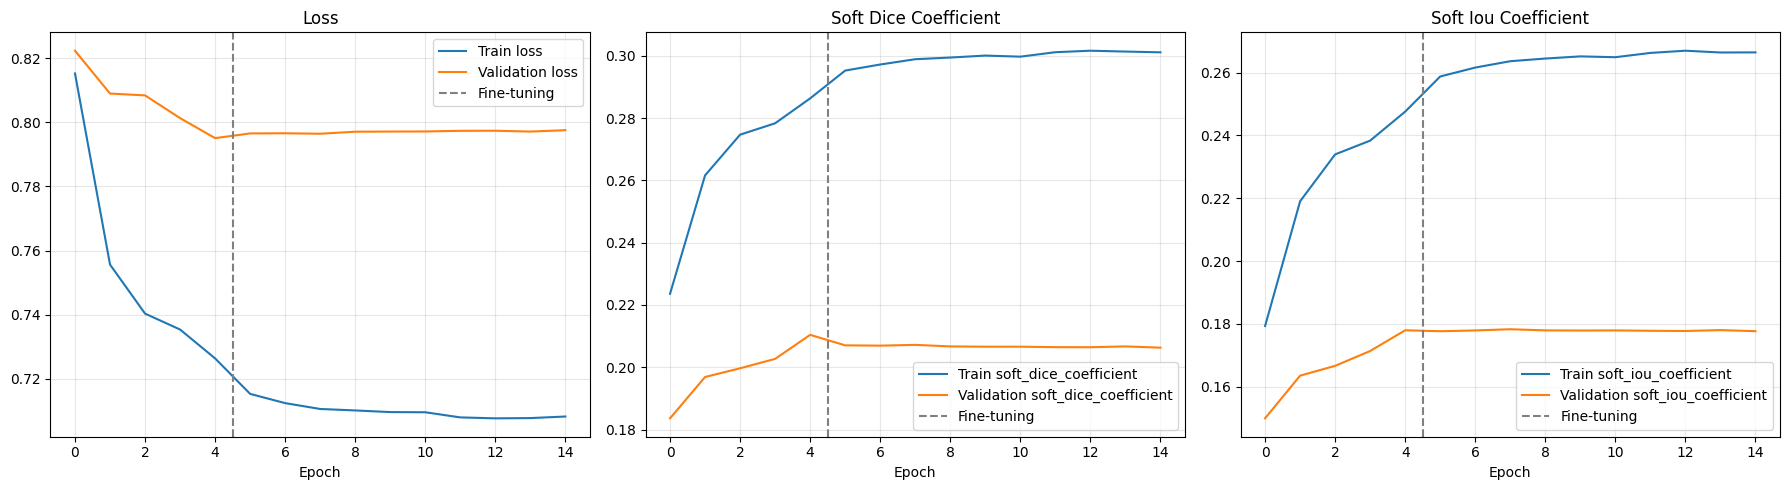

In [14]:
def merge_histories(*histories):
    merged = {}
    for history_item in histories:
        for metric_name, values in history_item.history.items():
            merged.setdefault(metric_name, []).extend(values)
    return merged

history = merge_histories(history_warmup, history_finetune)
metrics_to_plot = ["loss", "soft_dice_coefficient", "soft_iou_coefficient"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for axis, metric_name in zip(axes, metrics_to_plot):
    axis.plot(history[metric_name], label=f"Train {metric_name}")
    axis.plot(history[f"val_{metric_name}"], label=f"Validation {metric_name}")
    axis.axvline(
        completed_warmup_epochs - 0.5,
        color="gray",
        linestyle="--",
        label="Fine-tuning"
    )
    axis.set_title(metric_name.replace("_", " ").title())
    axis.set_xlabel("Epoch")
    axis.grid(alpha=0.3)
    axis.legend()

plt.tight_layout()
plt.savefig("training_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Validation threshold selection

The decision threshold is selected exclusively on validation predictions. Test predictions remain untouched until the threshold is fixed.

In [15]:
def collect_predictions(dataset, model):
    true_batches = []
    probability_batches = []

    for images, masks in dataset:
        probabilities = model.predict_on_batch(images)
        true_batches.append(masks.numpy().astype(np.uint8))
        probability_batches.append(np.asarray(probabilities, dtype=np.float16))

    return np.concatenate(true_batches), np.concatenate(probability_batches)

def compute_segmentation_metrics(y_true, y_probability, threshold):
    true_flat = y_true.reshape(len(y_true), -1) > 0.5
    pred_flat = y_probability.reshape(len(y_probability), -1) > threshold

    intersection = np.logical_and(true_flat, pred_flat).sum(axis=1).astype(np.float64)
    true_pixels = true_flat.sum(axis=1).astype(np.float64)
    pred_pixels = pred_flat.sum(axis=1).astype(np.float64)
    union = true_pixels + pred_pixels - intersection

    dice_denominator = true_pixels + pred_pixels
    per_image_dice = np.divide(
        2.0 * intersection,
        dice_denominator,
        out=np.ones_like(intersection),
        where=dice_denominator > 0
    )
    per_image_iou = np.divide(
        intersection,
        union,
        out=np.ones_like(intersection),
        where=union > 0
    )

    positive_cases = true_pixels > 0
    empty_cases = ~positive_cases

    tp = intersection.sum()
    fp = pred_pixels.sum() - tp
    fn = true_pixels.sum() - tp
    tn = np.logical_and(~true_flat, ~pred_flat).sum(dtype=np.float64)

    return {
        "threshold": float(threshold),
        "global_dice": float((2.0 * tp) / max(2.0 * tp + fp + fn, 1.0)),
        "global_iou": float(tp / max(tp + fp + fn, 1.0)),
        "mean_dice_all": float(per_image_dice.mean()),
        "mean_iou_all": float(per_image_iou.mean()),
        "mean_dice_positive": float(per_image_dice[positive_cases].mean()),
        "mean_iou_positive": float(per_image_iou[positive_cases].mean()),
        "precision": float(tp / max(tp + fp, 1.0)),
        "recall_sensitivity": float(tp / max(tp + fn, 1.0)),
        "specificity": float(tn / max(tn + fp, 1.0)),
        "pixel_accuracy": float((tp + tn) / max(tp + tn + fp + fn, 1.0)),
        "empty_false_positive_rate": float(np.mean(pred_pixels[empty_cases] > 0))
    }

val_true, val_probability = collect_predictions(val_ds, model)
thresholds = np.round(np.arange(0.10, 0.91, 0.10), 2)
threshold_df = pd.DataFrame([
    compute_segmentation_metrics(val_true, val_probability, threshold)
    for threshold in thresholds
])
threshold_df

,threshold,global_dice,global_iou,mean_dice_all,mean_iou_all,mean_dice_positive,mean_iou_positive,precision,recall_sensitivity,specificity,pixel_accuracy,empty_false_positive_rate
0,0.1,0.718147,0.560241,0.461030,0.428446,0.761079,0.645690,0.592602,0.911184,0.996835,0.996404,0.657040
1,0.2,0.748022,0.597472,0.555942,0.524419,0.776087,0.664456,0.643835,0.892438,0.997506,0.996977,0.530686
2,0.3,0.762159,0.615716,0.614223,0.583038,0.780645,0.670207,0.673363,0.877930,0.997848,0.997245,0.451264
3,0.4,0.770978,0.627310,0.645052,0.614079,0.779727,0.670041,0.695817,0.864342,0.998091,0.997418,0.407942
4,0.5,0.777510,0.636005,0.675372,0.644762,0.777007,0.668607,0.715250,0.851643,0.998287,0.997550,0.364621
5,0.6,0.782152,0.642242,0.705590,0.675159,0.773925,0.666160,0.733337,0.837929,0.998460,0.997653,0.321300
6,0.7,0.785492,0.646757,0.732325,0.701933,0.767684,0.660055,0.752175,0.821896,0.998632,0.997743,0.281588
7,0.8,0.786438,0.648041,0.747598,0.717074,0.757547,0.649453,0.774200,0.799069,0.998822,0.997818,0.256318
8,0.9,0.781262,0.641042,0.767519,0.736326,0.736353,0.625890,0.806007,0.757991,0.999078,0.997866,0.220217


In [16]:
best_threshold_row = threshold_df.sort_values(
    ["global_dice", "empty_false_positive_rate"],
    ascending=[False, True]
).iloc[0]
best_threshold = float(best_threshold_row["threshold"])

print("Selected validation threshold:", best_threshold)
display(best_threshold_row.to_frame(name="value"))

Selected validation threshold: 0.8


,value
threshold,0.800000
global_dice,0.786438
global_iou,0.648041
mean_dice_all,0.747598
mean_iou_all,0.717074
mean_dice_positive,0.757547
mean_iou_positive,0.649453
precision,0.774200
recall_sensitivity,0.799069
specificity,0.998822


## 8. Final test evaluation

The following cell performs the one-time final evaluation using the threshold selected on the validation set. Pixel accuracy is included for completeness but should not be interpreted alone because most pixels belong to the background.

In [17]:
test_true, test_probability = collect_predictions(test_ds, model)
test_metrics = compute_segmentation_metrics(test_true, test_probability, best_threshold)
test_results_df = pd.DataFrame.from_dict(test_metrics, orient="index", columns=["value"])
test_results_df

,value
threshold,0.800000
global_dice,0.828257
global_iou,0.706859
mean_dice_all,0.626822
mean_iou_all,0.592191
mean_dice_positive,0.794793
mean_iou_positive,0.691719
precision,0.836169
recall_sensitivity,0.820494
specificity,0.998019


In [18]:
threshold_df.to_csv("validation_threshold_results.csv", index=False)
test_results_df.to_csv("test_metrics.csv")
split_df.to_csv("dataset_split_summary.csv", index=False)

results_summary = {
    "seed": SEED,
    "image_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "selected_threshold": best_threshold,
    "test_metrics": test_metrics,
    "split_summary": split_df.to_dict(orient="records")
}

with open("results_summary.json", "w", encoding="utf-8") as file:
    json.dump(results_summary, file, indent=2)

print("Metric files saved.")

Metric files saved.


## 9. Prediction visualization

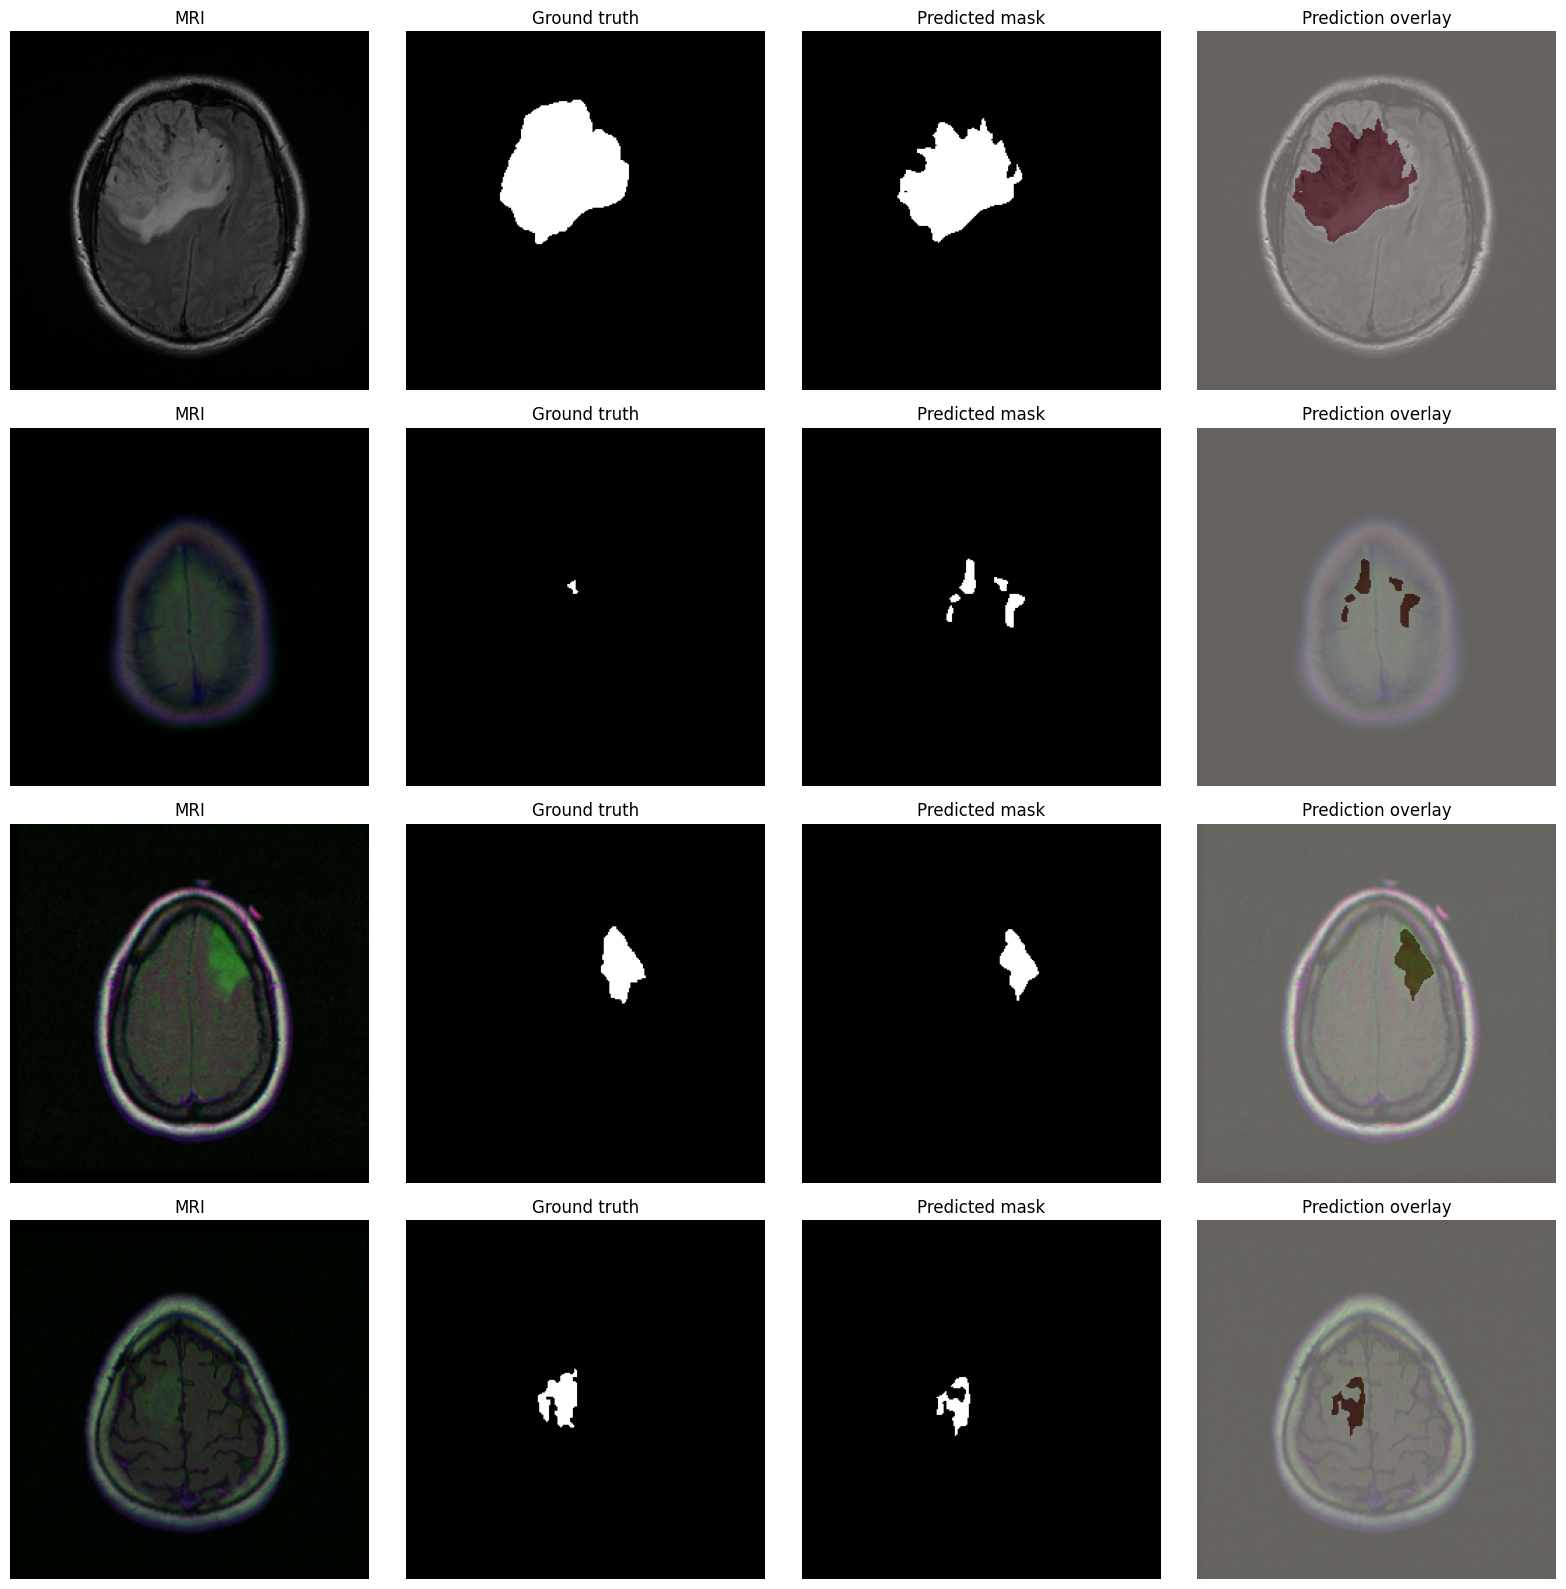

In [19]:
def denormalize_image(image):
    return np.clip((image + 1.0) / 2.0, 0.0, 1.0)

def visualize_positive_predictions(
    image_paths,
    mask_paths,
    model,
    threshold,
    num_samples=4,
    filename="prediction_results.png"
):
    positive_indices = [
        index for index, path in enumerate(mask_paths) if mask_is_positive(path)
    ]
    if not positive_indices:
        raise ValueError("No tumor-positive test slices were found.")

    sample_count = min(num_samples, len(positive_indices))
    selected_indices = np.random.default_rng(SEED).choice(
        positive_indices,
        size=sample_count,
        replace=False
    )

    fig, axes = plt.subplots(sample_count, 4, figsize=(16, 4 * sample_count))
    axes = np.atleast_2d(axes)

    for row, index in enumerate(selected_indices):
        image, mask = read_pair(image_paths[index], mask_paths[index])
        probability = model.predict(image[None, ...], verbose=0)[0, ..., 0]
        prediction = probability > threshold
        display_image = denormalize_image(image)

        axes[row, 0].imshow(display_image)
        axes[row, 0].set_title("MRI")
        axes[row, 1].imshow(mask[..., 0], cmap="gray")
        axes[row, 1].set_title("Ground truth")
        axes[row, 2].imshow(prediction, cmap="gray")
        axes[row, 2].set_title("Predicted mask")
        axes[row, 3].imshow(display_image)
        axes[row, 3].imshow(prediction, cmap="Reds", alpha=0.4)
        axes[row, 3].set_title("Prediction overlay")

        for axis in axes[row]:
            axis.axis("off")

    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

visualize_positive_predictions(
    test_images,
    test_masks,
    model,
    threshold=best_threshold
)

## Generated artifacts

After all cells finish, the runtime contains:

- best_deeplabv3plus_brain_mri.keras
- training_curves.png
- prediction_results.png
- validation_threshold_results.csv
- test_metrics.csv
- dataset_split_summary.csv
- results_summary.json

## Notes

This project is intended for research and educational use. It is not a clinical diagnostic system. For GitHub publication, run all cells in order and save the completed notebook so the final metrics and figures are visible.